# Linguistic Analysis

PCA/UMAP projections and distinctive-feature analysis of transcribed
medieval documents.

The pipeline reads PAGE-XML transcriptions, builds TF-IDF features over
whitespace-delimited tokens (so medieval MUFI glyphs survive as their own
tokens), and projects documents into a reduced space coloured by scribal
group. A handful of holdout documents are tracked through every plot and
checked against each group's chi2-ranked distinctive features.


## 1 — Imports & configuration

In [1]:
import os
import io
import json
import zipfile
import urllib.request
import warnings
from pathlib import Path
from xml.etree import ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.font_manager import FontProperties
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import chi2

sns.set_style("whitegrid")
mpl.rcParams["figure.dpi"] = 120
mpl.rcParams["figure.figsize"] = (10, 6)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Roboto Condensed']

In [2]:
INPUT_DIR    = Path("../data/deeds-page")
EXCEL_PATH   = "../data/misc-assets/clusterings.xlsx"
TXT_DIR      = Path("../data/deeds-txt")

MIN_DOCS     = 15                # minimum docs per scribe
TOP_N_GROUPS = 3                 # groups for the classifier

# "controversial" early docs, tentatively attributed to R:
HOLDOUT_IDS = [
    "0216_14_08_1313-01",
    "0437_30_12_1311-01",
    "0334_22_04_1311-01",
    "0218_14_09_1311-01",
    "0352_24_06_1312-01",
]

HIGHLIGHT_COLOR = "#222222"

## 2 — Medieval-glyph font

Transcriptions contain MUFI characters from the Latin Extended-D block
(e.g. ꞩ, ꝑ, ꝫ) that Arial/DejaVu cannot render, producing "missing glyph"
warnings in plots. Junicode (OFL, by Peter S. Baker) covers them. The helper
below downloads the static instances once, caches them under `~/.fonts`,
registers every weight with matplotlib, and returns a `FontProperties` for
the requested style. Pin a `version` for byte-identical output across
machines.


In [3]:
def ensure_junicode(version=None, cache_dir=None, style="Regular"):
    """Download (once) + register Junicode static instances; return a FontProperties.
       version: e.g. "2.224" to pin an exact release, or None for latest.
       style:   static instance for the returned FontProperties, e.g. "Regular", "Bold"."""
    cache_dir = Path(cache_dir or (Path.home() / ".fonts" / "junicode"))
    cache_dir.mkdir(parents=True, exist_ok=True)

    have = [f for f in cache_dir.glob("Junicode-*.ttf") if "VF" not in f.name]
    if not have:
        api = ("https://api.github.com/repos/psb1558/Junicode-font/releases/"
               + (f"tags/v{version}" if version else "latest"))
        rel = json.load(urllib.request.urlopen(api))
        zip_url = next(a["browser_download_url"] for a in rel["assets"]
                       if a["name"].lower().endswith(".zip"))
        blob = urllib.request.urlopen(zip_url).read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            for n in z.namelist():
                base = Path(n).name
                if base.startswith("Junicode-") and base.endswith(".ttf") and "VF" not in base:
                    (cache_dir / base).write_bytes(z.read(n))
        have = [f for f in cache_dir.glob("Junicode-*.ttf") if "VF" not in f.name]

    for f in have:
        font_manager.fontManager.addfont(str(f))

    want = cache_dir / f"Junicode-{style}.ttf"
    if not want.exists():
        raise FileNotFoundError(f"{want.name} missing; have: {sorted(f.name for f in have)}")
    return FontProperties(fname=str(want))


# JFP is the upright roman used for all medieval-glyph labels in the plots.
JFP = ensure_junicode()            # latest release; pass e.g. "2.224" to pin
print("Junicode ready:", JFP.get_name())

Junicode ready: Junicode


## 3 — Extract transcriptions from PAGE XML

In [4]:
PAGE_NS = {"p": "http://schema.primaresearch.org/PAGE/gts/pagecontent/2013-07-15"}
TXT_DIR.mkdir(exist_ok=True)

xml_files = sorted(INPUT_DIR.glob("*.xml"))
print(f"Found {len(xml_files)} XML file(s) in '{INPUT_DIR}'.\n")

for xml_path in xml_files:
    tree = ET.parse(xml_path)
    root = tree.getroot()
    lines = []
    for region in root.findall(".//p:TextRegion", PAGE_NS):
        for text_line in region.findall("p:TextLine", PAGE_NS):
            unicode_el = text_line.find("p:TextEquiv/p:Unicode", PAGE_NS)
            if unicode_el is not None and unicode_el.text:
                lines.append(unicode_el.text)
    out_path = TXT_DIR / (xml_path.stem + ".txt")
    out_path.write_text("\n".join(lines), encoding="utf-8")
    print(f"  {xml_path.name}  →  {out_path.name}  ({len(lines)} lines)")

print(f"\nDone. {len(xml_files)} file(s) written to '{TXT_DIR}'.")

Found 470 XML file(s) in '../data/deeds-page'.

  0001_01_01_1332-01.xml  →  0001_01_01_1332-01.txt  (13 lines)
  0002_01_01_1335-01.xml  →  0002_01_01_1335-01.txt  (13 lines)
  0003_01_01_1346-01.xml  →  0003_01_01_1346-01.txt  (23 lines)
  0004_01_01_1349-01.xml  →  0004_01_01_1349-01.txt  (15 lines)
  0005_01_02_1341-01.xml  →  0005_01_02_1341-01.txt  (7 lines)
  0006_01_03_1319-01.xml  →  0006_01_03_1319-01.txt  (10 lines)
  0007_01_03_1331-01.xml  →  0007_01_03_1331-01.txt  (9 lines)
  0008_01_03_1348-01.xml  →  0008_01_03_1348-01.txt  (13 lines)
  0009_01_03_1352-01.xml  →  0009_01_03_1352-01.txt  (20 lines)
  0010_01_03_1354-01.xml  →  0010_01_03_1354-01.txt  (10 lines)
  0011_01_04_1337-01.xml  →  0011_01_04_1337-01.txt  (17 lines)
  0012_01_05_1302-01.xml  →  0012_01_05_1302-01.txt  (20 lines)
  0013_01_05_1328-01.xml  →  0013_01_05_1328-01.txt  (9 lines)
  0014_01_07_1349-01.xml  →  0014_01_07_1349-01.txt  (13 lines)
  0015_01_07_1349-02.xml  →  0015_01_07_1349-02.txt  (15 li

## 4 — Load metadata & texts

In [5]:
meta = pd.read_excel(EXCEL_PATH)
counts = meta["group-adjusted"].value_counts()
keep_groups = counts[
    (counts >= MIN_DOCS) & (~counts.index.isin([-1, "-1"]))
].index
meta = meta[meta["group-adjusted"].isin(keep_groups)].copy()

# Build filename-stem -> txt-file lookup
txt_stems = {
    os.path.splitext(f)[0]: f
    for f in os.listdir(TXT_DIR) if f.endswith(".txt")
}

def load_texts_from_meta(meta_df):
    """Match metadata rows to their transcribed .txt files."""
    texts, ids, groups = [], [], []
    for _, row in meta_df.iterrows():
        stem = os.path.splitext(str(row["filename"]))[0]
        if stem in txt_stems:
            txt_path = os.path.join(TXT_DIR, txt_stems[stem])
            with open(txt_path, encoding="utf-8") as f:
                texts.append(f.read())
            ids.append(stem)
            groups.append(row["group-adjusted"])
    return pd.DataFrame({"id": ids, "group": groups, "text": texts})

df = load_texts_from_meta(meta)
print(f"Loaded {len(df)} documents across {df['group'].nunique()} groups")
print(df["group"].value_counts().sort_values(ascending=False))

Loaded 407 documents across 6 groups
group
R    217
S     82
P     48
O     27
Q     18
E     15
Name: count, dtype: int64


## 5 — Helper functions

`_distinctive_features` ranks each class's most characteristic features;
`plot_projection_scatter` draws the PCA/UMAP scatter with per-class feature
boxes and highlighted holdout documents. `print_top_loadings` and the two
string-distance helpers support the R-vs-S sections further down.


In [6]:
def _distinctive_features(M, class_labels, feature_names, k=5):
    """Top-k features per class by chi-squared dependence on a one-vs-rest
    class indicator, restricted to features that are *enriched* in the class.
    Returns {class: [feature, ...]} — same shape as before.

    NOTE: chi2 requires non-negative features. Pass the (non-negative) TF-IDF
    matrix here (e.g. X_tfidf / X_rs), NOT the StandardScaler output X_scaled.
    """
    feature_names = np.asarray(feature_names)
    class_labels  = np.asarray(class_labels)

    if M.min() < 0:
        raise ValueError(
            "_distinctive_features uses chi2, which needs non-negative features. "
            "Pass the TF-IDF matrix (e.g. X_tfidf), not X_scaled."
        )

    out = {}
    for c in pd.unique(class_labels):
        if c is None or (isinstance(c, float) and np.isnan(c)):
            continue
        idx_in  = np.where(class_labels == c)[0]
        idx_out = np.where(class_labels != c)[0]
        if idx_in.size == 0 or idx_out.size == 0:
            continue

        y_bin = (class_labels == c).astype(int)
        scores, _ = chi2(M, y_bin)
        scores = np.nan_to_num(scores, nan=-np.inf)

        # Keep only features over-represented in the class, so we don't surface
        # features that are "distinctive" by their absence.
        in_mean  = np.asarray(M[idx_in].mean(0)).ravel()
        out_mean = np.asarray(M[idx_out].mean(0)).ravel()
        masked = np.where(in_mean > out_mean, scores, -np.inf)

        top = np.argsort(masked)[-k:][::-1]
        out[c] = [feature_names[j] for j in top if np.isfinite(masked[j])]
    return out

In [7]:
def plot_projection_scatter(documents_proj, labels,
                            feature_names=None, feature_matrix=None,
                            highlight_ids=None, doc_ids=None,
                            highlight_labels=None,
                            doc_colors=None, color_label_map=None,
                            n_umap_pcs=None,
                            umap_kwargs=None, random_state=42,
                            annotate=False, point_size=60,
                            class_labels=None, show_class_features=False,
                            n_class_features=5, class_features_per_line=2,
                            class_fontprops=None,
                            highlight_color=HIGHLIGHT_COLOR,
                            title=None, out_filename=None):
    documents_proj = np.asarray(documents_proj)
    fp = class_fontprops if class_fontprops is not None else globals().get("JFP")

    try:
        import umap
    except ImportError:
        warnings.warn("plot_projection_scatter requires 'umap-learn'; skipping.")
        return

    n_avail = documents_proj.shape[1]
    k = n_avail if n_umap_pcs is None else min(n_umap_pcs, n_avail)
    reducer = umap.UMAP(n_components=2, random_state=random_state,
                        **(umap_kwargs or {}))
    emb = reducer.fit_transform(documents_proj[:, :k])
    x1, x2 = emb[:, 0], emb[:, 1]
    xlabel, ylabel = "UMAP-1", "UMAP-2"


    fig, ax = plt.subplots(figsize=(11, 9))

    if highlight_ids and doc_ids is not None:
        doc_ids = np.asarray(doc_ids)
        hl_mask = np.array([d in highlight_ids for d in doc_ids])
    else:
        hl_mask = np.zeros(len(labels), dtype=bool)
    norm = ~hl_mask

    if doc_colors is not None:
        doc_colors = list(doc_colors)
        if color_label_map:
            from collections import OrderedDict
            groups = OrderedDict()
            for idx in np.where(norm)[0]:
                groups.setdefault(doc_colors[idx], []).append(idx)
            for color, idxs in groups.items():
                idxs = np.array(idxs)
                ax.scatter(x1[idxs], x2[idxs], s=point_size, color=color,
                           alpha=0.75, edgecolors="white", linewidths=0.5)
        else:
            idxs = np.where(norm)[0]
            ax.scatter(x1[idxs], x2[idxs], s=point_size,
                       color=[doc_colors[i] for i in idxs],
                       alpha=0.75, edgecolors="white", linewidths=0.5)
    else:
        idxs = np.where(norm)[0]
        ax.scatter(x1[idxs], x2[idxs], s=point_size, alpha=0.75,
                   edgecolors="white", linewidths=0.5)

    if annotate:
        for idx in np.where(norm)[0]:
            ax.text(x1[idx], x2[idx], labels[idx], ha="center", va="center",
                    fontsize=8, alpha=0.8)

    if hl_mask.any():
        ax.scatter(x1[hl_mask], x2[hl_mask], marker="^", s=170,
                   c=highlight_color, edgecolors="white", linewidths=1.0,
                   zorder=5)
        y_range = (x2.max() - x2.min()) or 1.0
        offset = y_range * 0.02
        for p1, p2, did in zip(x1[hl_mask], x2[hl_mask], doc_ids[hl_mask]):
            display = highlight_labels.get(did, did) if highlight_labels else did
            ax.text(p1, p2 + offset, display, ha="center", va="bottom",
                    fontsize=9, fontweight="bold", color=highlight_color,
                    alpha=0.95)

    if show_class_features:
        if feature_matrix is None or feature_names is None or class_labels is None:
            warnings.warn("show_class_features=True needs feature_matrix, "
                          "feature_names and class_labels; skipping.")
        else:
            class_labels = np.asarray(class_labels)
            cls_feats = _distinctive_features(feature_matrix, class_labels,
                                              feature_names, n_class_features)
            dcl = list(doc_colors) if doc_colors is not None else None

            def _cls_color(c):
                if dcl is None:
                    return "0.2"
                for idx in np.where(class_labels == c)[0]:
                    if dcl[idx] != highlight_color:
                        return dcl[idx]
                return "0.2"

            fpl = max(1, class_features_per_line)
            for c, feats in cls_feats.items():
                m = class_labels == c
                if m.sum() == 0:
                    continue
                gx, gy = x1[m].mean(), x2[m].mean()
                lines = [", ".join(feats[i:i + fpl])
                         for i in range(0, len(feats), fpl)]
                body = ",\n".join(lines)
                col = _cls_color(c)
                ax.annotate(f"{str(c).upper()}\n{body}", (gx, gy),
                            ha="center", va="center", fontsize=12, zorder=9,
                            fontproperties=fp,
                            bbox=dict(boxstyle="round,pad=0.3", fc="white",
                                      ec=col, lw=1.6, alpha=0.5))

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    if out_filename:
        plt.savefig(out_filename, dpi=300, bbox_inches='tight')
    plt.show()
    

## 6 — UMAP projection of all groups

TF-IDF over whitespace tokens, standardized, reduced to `N_PCS` principal
components, then projected to 2-D with UMAP. Each class centroid is labelled
with its most distinctive features; holdout documents are marked and tagged
with their year.


TF-IDF matrix: 407 docs × 869 features


/Users/mikekestemont/miniconda3/envs/bayes/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


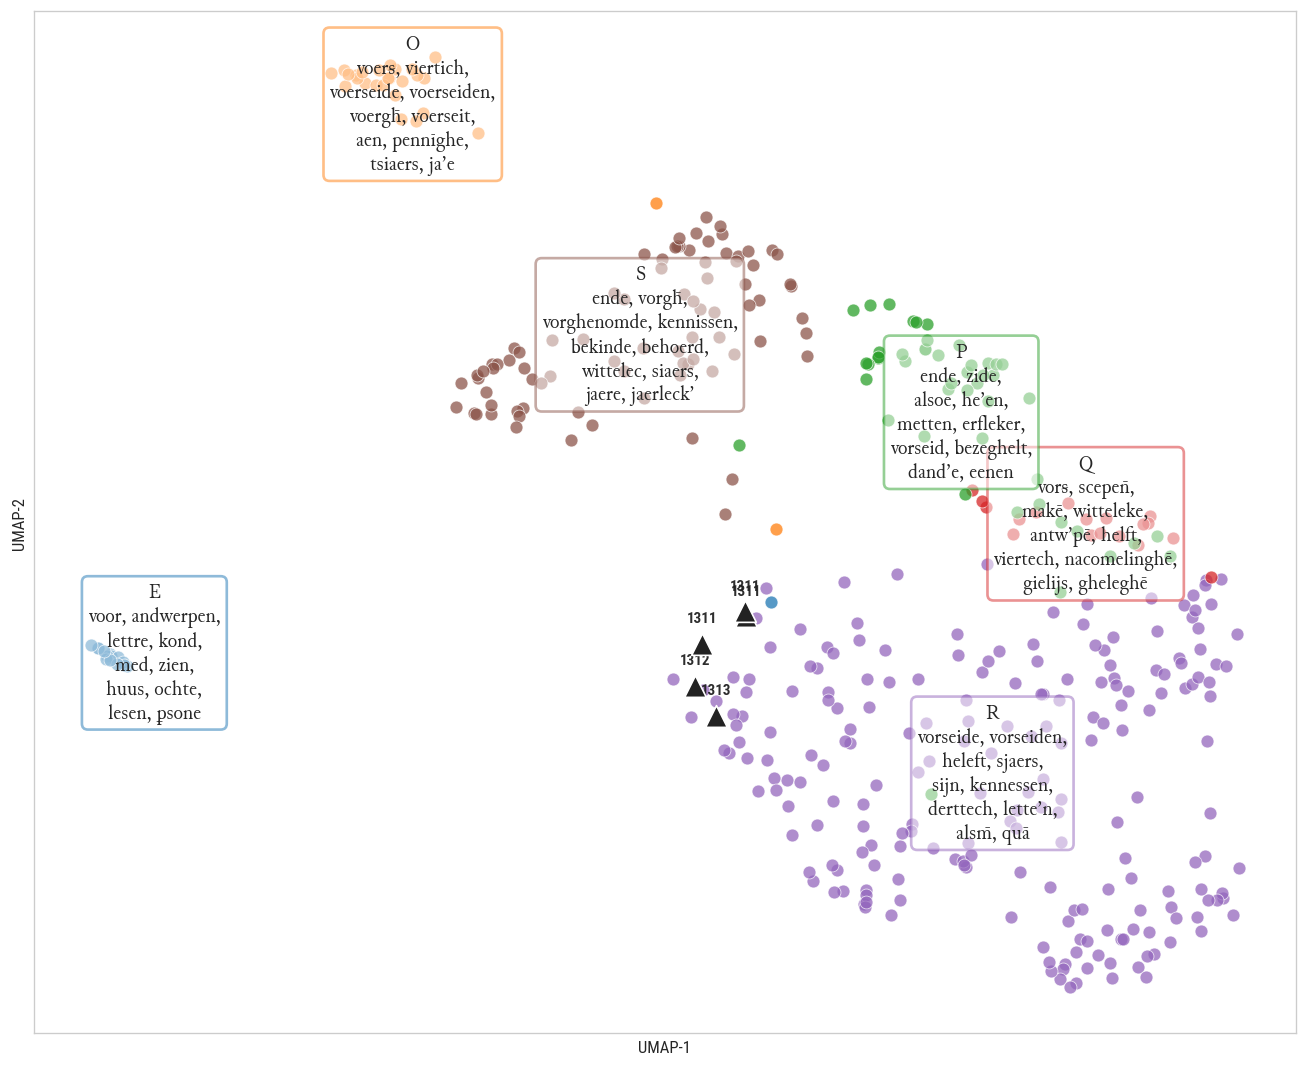

In [8]:
N_PCS = 30

vectorizer = TfidfVectorizer(
    lowercase=True, analyzer="word", ngram_range=(1, 1),
    token_pattern=r"\S+",
    min_df=10, max_df=0.95, use_idf=False,
)
X_tfidf = vectorizer.fit_transform(df["text"])
feature_names = vectorizer.get_feature_names_out()
print(f"TF-IDF matrix: {X_tfidf.shape[0]} docs × {X_tfidf.shape[1]} features")

X_scaled = StandardScaler(with_mean=True, with_std=True).fit_transform(X_tfidf.toarray())
n_comp_all = min(N_PCS, X_scaled.shape[0] - 1, X_scaled.shape[1])
pca_all = PCA(n_components=n_comp_all, random_state=42)
docs_proj_all = pca_all.fit_transform(X_scaled)

# Extract year from doc ID  (e.g. "0216_14_08_1313-01" -> "1313")
highlight_labels = {
    doc_id: doc_id.split("_")[3].split("-")[0] for doc_id in HOLDOUT_IDS
}

categories = df["group"].values
unique_cats = sorted(set(categories))
cmap = mpl.colormaps["tab10"]
cat_to_color = {cat: cmap(i) for i, cat in enumerate(unique_cats)}

doc_colors = [cat_to_color[cat] for cat in categories]
color_label_map = {cat_to_color[cat]: cat for cat in unique_cats}

plot_projection_scatter(
    docs_proj_all,
    labels=df["group"].values,
    feature_names=feature_names,
    highlight_ids=set(HOLDOUT_IDS),
    doc_ids=df["id"].values,
    highlight_labels=highlight_labels,
    doc_colors=doc_colors,
    color_label_map=color_label_map,
    n_umap_pcs=n_comp_all,
    feature_matrix=X_tfidf,
    class_labels=df["group"].values,
    show_class_features=True, n_class_features=10,
    out_filename='../outputs/stylo.png'
);

Which of class R's UMAP-displayed distinctive features appear in the holdouts?

In [9]:
CLASS = "R"
K     = 10

feats = _distinctive_features(X_tfidf, df["group"].values, feature_names, k=K)[CLASS]
print(f"{CLASS}'s distinctive features (k={K}): {feats}\n")

holdout = df[df["id"].isin(HOLDOUT_IDS)]
missing = set(HOLDOUT_IDS) - set(holdout["id"])
if missing:
    print(f"!! holdout ids not found in df: {sorted(missing)}\n")

for _, row in holdout.iterrows():
    toks = row["text"].lower().split()           # mirrors the vectorizer: lowercase + \S+
    tset = set(toks)
    hits = [(f, toks.count(f)) for f in feats if f in tset]
    if hits:
        detail = ", ".join(f"{f}×{n}" for f, n in hits)
        print(f"{row['id']} (group {row['group']}): {len(hits)}/{K} hits -> {detail}")
    else:
        print(f"{row['id']} (group {row['group']}): no hits")

R's distinctive features (k=10): ['vorseide', 'vorseiden', 'heleft', 'sjaers', 'sijn', 'kennessen', 'derttech', 'letteʼn', 'alsm̄', 'quā']

0216_14_08_1313-01 (group R): 4/10 hits -> vorseide×1, sjaers×1, sijn×3, letteʼn×1
0218_14_09_1311-01 (group R): 3/10 hits -> vorseide×1, vorseiden×2, sijn×1
0334_22_04_1311-01 (group R): 2/10 hits -> heleft×4, quā×1
0352_24_06_1312-01 (group R): 6/10 hits -> vorseide×1, vorseiden×1, heleft×2, sjaers×1, sijn×1, letteʼn×1
0437_30_12_1311-01 (group R): 3/10 hits -> vorseide×2, vorseiden×2, sijn×6
